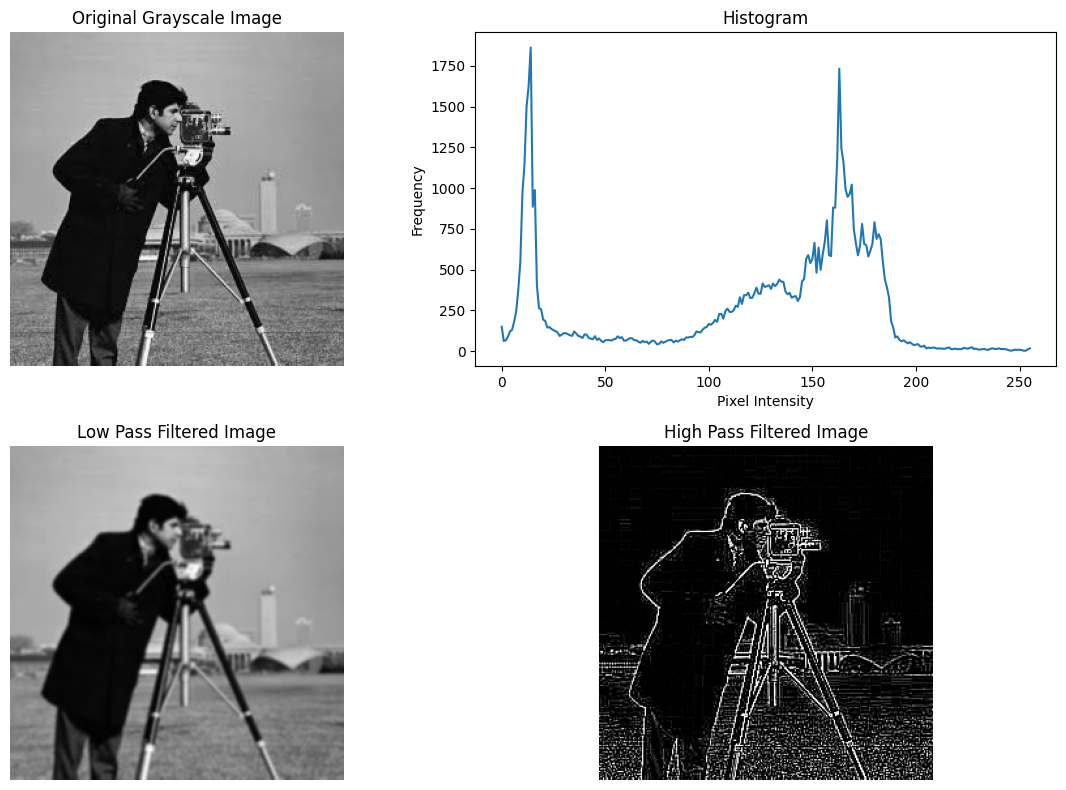

In [1]:
# Display following image operation in MATLAB/Python - i) Histogram  
# image  ii) Low pass filter mage  iii) High pass image. 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------
# Read Image
# --------------------------------

img = cv2.imread("cameraman.jpg")

# Check if image loaded properly
if img is None:
    print("Error: Image not found. Check the file path/name.")
    exit()

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# --------------------------------
# i) Histogram
# --------------------------------

hist = cv2.calcHist([gray], [0], None, [256], [0, 256])

# --------------------------------
# ii) Low Pass Filter
# --------------------------------

low_pass = cv2.GaussianBlur(gray, (5, 5), 0)

# --------------------------------
# iii) High Pass Filter
# --------------------------------

kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

high_pass = cv2.filter2D(gray, -1, kernel)

# --------------------------------
# Display Results
# --------------------------------

plt.figure(figsize=(12, 8))

# Original Image
plt.subplot(2, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

# Histogram
plt.subplot(2, 2, 2)
plt.plot(hist)
plt.title('Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')

# Low Pass Filter
plt.subplot(2, 2, 3)
plt.imshow(low_pass, cmap='gray')
plt.title('Low Pass Filtered Image')
plt.axis('off')

# High Pass Filter
plt.subplot(2, 2, 4)
plt.imshow(high_pass, cmap='gray')
plt.title('High Pass Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()

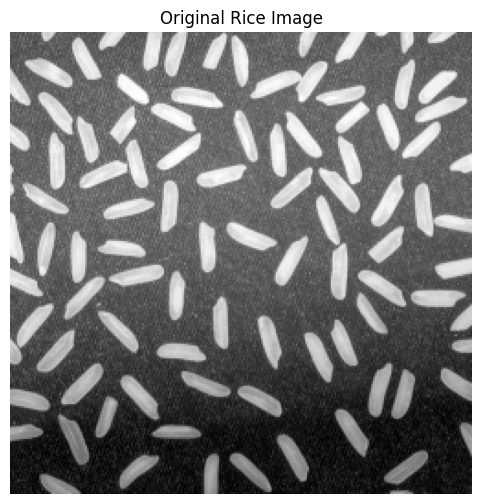

Number of rice grains: 83

Rice No.	Area		Major Axis Length	Perimeter
-----------------------------------------------------------------
1		85.00		14.37			34.73
2		163.00		23.27			53.31
3		195.00		26.91			61.21
4		89.00		14.95			36.73
5		154.00		21.79			52.04
6		65.00		11.61			29.66
7		66.00		14.38			31.28
8		144.00		22.10			51.21
9		188.00		29.03			62.97
10		197.00		26.97			61.11
11		213.00		28.52			64.28
12		425.00		45.79			122.81
13		195.00		28.25			62.38
14		193.00		26.74			58.18
15		113.00		19.55			45.80
16		162.00		23.27			52.53
17		188.00		28.00			61.80
18		232.00		29.90			67.21
19		210.00		28.92			63.60
20		208.00		30.50			67.70
21		152.00		23.25			50.77
22		205.00		27.51			63.46
23		188.00		27.25			60.28
24		159.00		21.37			51.70
25		199.00		31.08			66.87
26		224.00		30.85			67.01
27		186.00		26.39			60.63
28		193.00		28.26			61.01
29		211.00		30.61			65.56
30		104.00		15.68			38.97
31		222.00		30.95			67.31
32		206.00		30.52			65.60
33		442.00		40.38			131.05
34		419.00		43.81

C:\Users\HP\AppData\Local\Temp\ipykernel_26520\3205357832.py:52: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  f"{prop.major_axis_length:.2f}\t\t\t"


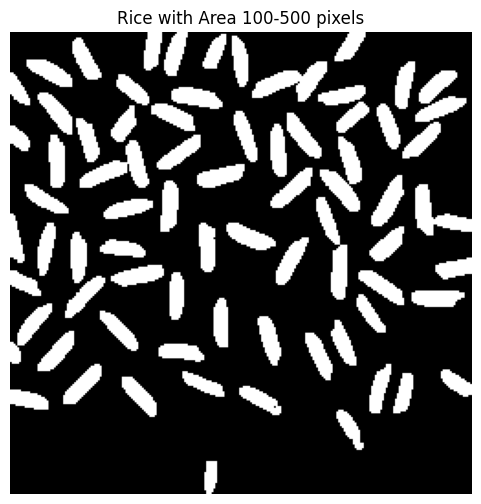

In [2]:
# Write a MATLAB/Python program to read ‘rice.tif’ image, count number of 
# rice and display area (also specific range), major axis length, and perimeter. 

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops

# Read rice image
image = cv2.imread("rice.tif", cv2.IMREAD_GRAYSCALE)

# Display original image
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("Original Rice Image")
plt.axis("off")
plt.show()

# Convert image to binary
_, binary = cv2.threshold(
    image, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# Label connected rice grains
label_image = label(binary > 0)

# Measure properties
properties = regionprops(label_image)

# Remove very small objects
properties = [p for p in properties if p.area > 50]

# Number of rice grains
number_of_rice = len(properties)

print("Number of rice grains:", number_of_rice)
print()

# Display measurements
print("Rice No.\tArea\t\tMajor Axis Length\tPerimeter")
print("-" * 65)

for i, prop in enumerate(properties, start=1):
    print(
        f"{i}\t\t"
        f"{prop.area:.2f}\t\t"
        f"{prop.major_axis_length:.2f}\t\t\t"
        f"{prop.perimeter:.2f}"
    )

# ---------------------------------------
# Specific Area Range
# ---------------------------------------

min_area = 100
max_area = 500

selected_rice = [
    p for p in properties
    if min_area <= p.area <= max_area
]

print()
print(f"Rice with area between {min_area} and {max_area}: "
      f"{len(selected_rice)}")

# Display selected rice grains
selected_image = np.zeros_like(label_image)

for p in selected_rice:
    selected_image[label_image == p.label] = 1

plt.figure(figsize=(6, 6))
plt.imshow(selected_image, cmap="gray")
plt.title(
    f"Rice with Area {min_area}-{max_area} pixels"
)
plt.axis("off")
plt.show()

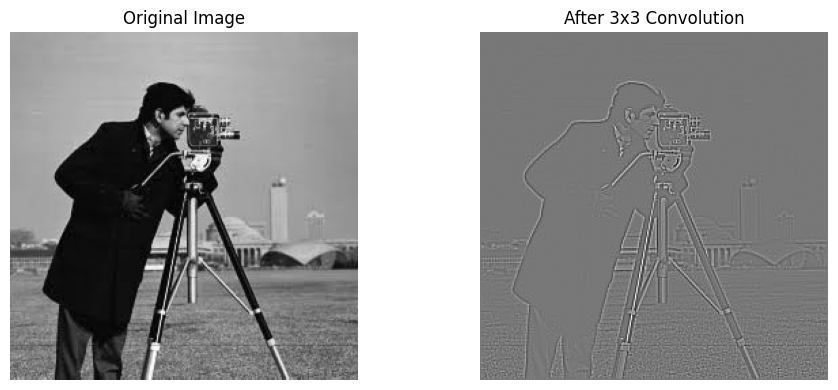

In [3]:
 
# Write a MATLAB/Python program to read an image and perform 
# convolution with 3X3 mask. 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
image = cv2.imread("cameraman.jpg", cv2.IMREAD_GRAYSCALE)

# 3x3 mask
mask = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# Get image dimensions
rows, cols = image.shape

# Create output image
output = np.zeros((rows, cols), dtype=np.float32)

# Perform convolution manually
for i in range(1, rows - 1):
    for j in range(1, cols - 1):

        region = image[i-1:i+2, j-1:j+2]

        output[i, j] = np.sum(region * mask)

# Normalize result for display
output = cv2.normalize(
    output,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Display
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output, cmap="gray")
plt.title("After 3x3 Convolution")
plt.axis("off")

plt.tight_layout()
plt.show()


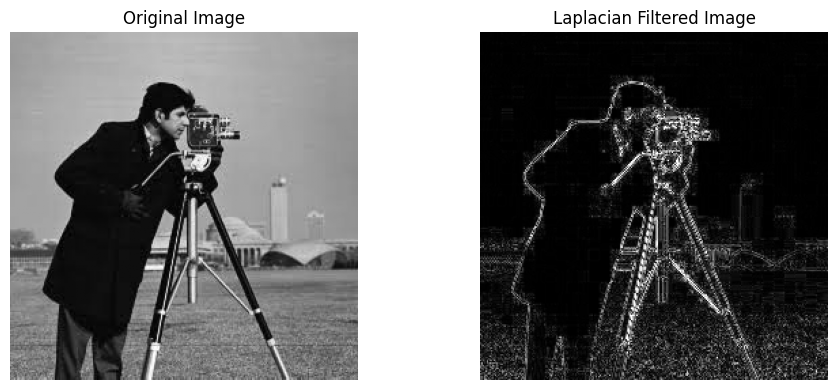

In [4]:
# Write a MATLAB/Python program to read an image and perform Lapliciant 
# filter mask. 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
image = cv2.imread("cameraman.jpg", cv2.IMREAD_GRAYSCALE)

# Define 3x3 Laplacian filter mask
mask = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
])

# Apply Laplacian filter
laplacian = cv2.filter2D(image, cv2.CV_64F, mask)

# Convert result to displayable image
laplacian = np.absolute(laplacian)
laplacian = np.uint8(np.clip(laplacian, 0, 255))

# Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

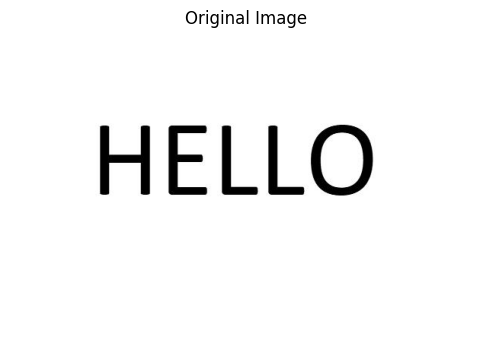

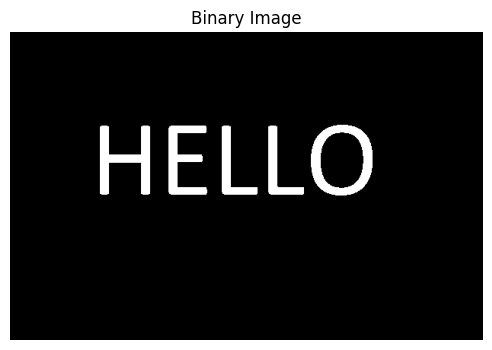

Number of segmented characters: 5


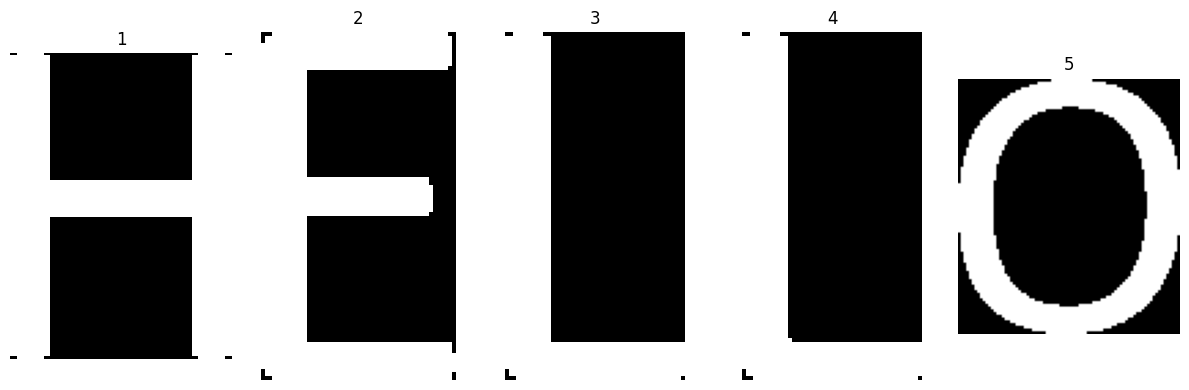

In [5]:
# Write a MATLAB/Python program to Character Segment of an image.  

import cv2
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------
# 1. Read the image
# -----------------------------------
image = cv2.imread( "image6.jpg", cv2.IMREAD_GRAYSCALE)

# Display original image
plt.figure(figsize=(10, 4))
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

# -----------------------------------
# 2. Convert image to binary
# -----------------------------------
_, binary = cv2.threshold(
    image, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Display binary image
plt.figure(figsize=(10, 4))
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()

# -----------------------------------
# 3. Find connected components
# -----------------------------------
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    binary,
    connectivity=8
)

# List to store character images
characters = []

# -----------------------------------
# 4. Extract individual characters
# -----------------------------------
for i in range(1, num_labels):

    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]
    area = stats[i, cv2.CC_STAT_AREA]

    # Remove very small noise
    if area > 20:

        character = binary[y:y+h, x:x+w]

        characters.append((x, y, w, h, character))

# Sort characters from left to right
characters.sort(key=lambda c: c[0])

# -----------------------------------
# 5. Display segmented characters
# -----------------------------------

print("Number of segmented characters:", len(characters))

plt.figure(figsize=(12, 4))

for i, (x, y, w, h, character) in enumerate(characters):

    plt.subplot(1, len(characters), i + 1)
    plt.imshow(character, cmap="gray")
    plt.title(str(i + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()


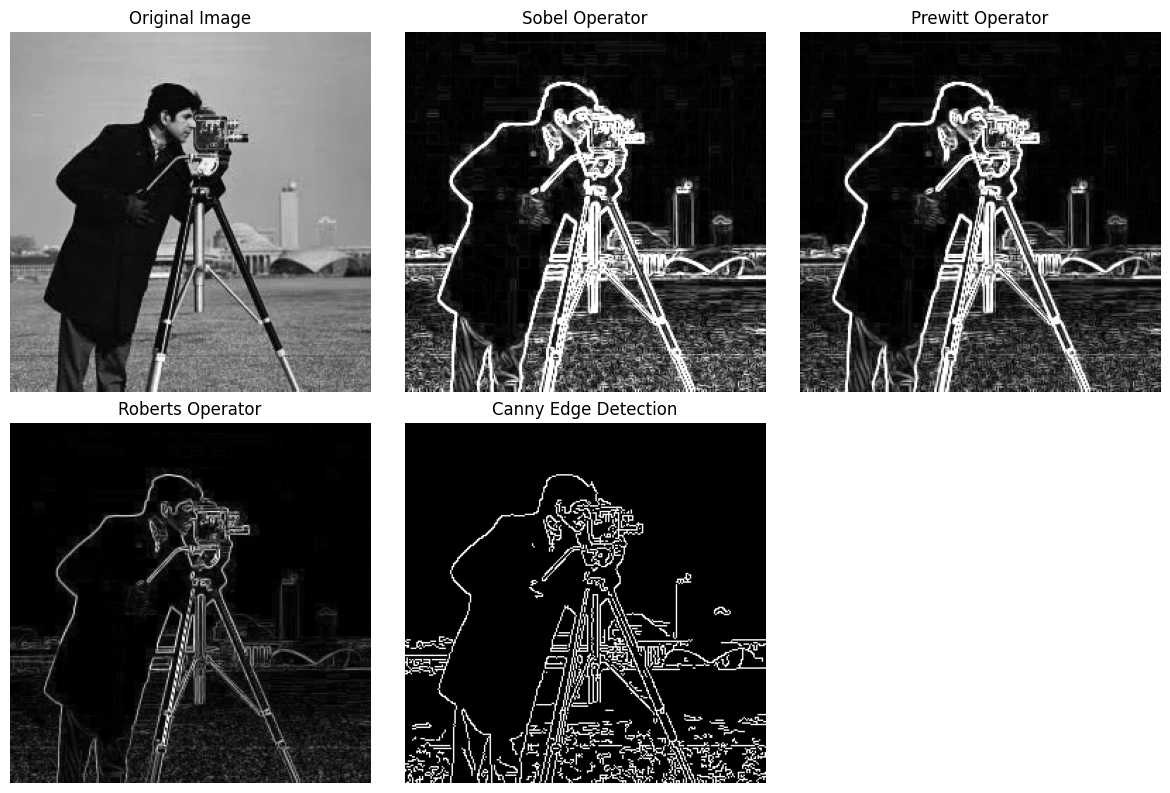

In [6]:
# For the given image perform edge detection using different operators and 
# compare the results.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 1. Read the image
# ---------------------------------------
image = cv2.imread("cameraman.jpg", cv2.IMREAD_GRAYSCALE)

# ---------------------------------------
# 2. Sobel Edge Detection
# ---------------------------------------
sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)

sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel)

# ---------------------------------------
# 3. Prewitt Edge Detection
# ---------------------------------------
prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

prewitt_y = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
])

px = cv2.filter2D(image, cv2.CV_64F, prewitt_x)
py = cv2.filter2D(image, cv2.CV_64F, prewitt_y)

prewitt = cv2.magnitude(px, py)
prewitt = cv2.convertScaleAbs(prewitt)

# ---------------------------------------
# 4. Roberts Edge Detection
# ---------------------------------------
roberts_x = np.array([
    [1, 0],
    [0, -1]
])

roberts_y = np.array([
    [0, 1],
    [-1, 0]
])

rx = cv2.filter2D(image, cv2.CV_64F, roberts_x)
ry = cv2.filter2D(image, cv2.CV_64F, roberts_y)

roberts = cv2.magnitude(rx, ry)
roberts = cv2.convertScaleAbs(roberts)

# ---------------------------------------
# 5. Canny Edge Detection
# ---------------------------------------
canny = cv2.Canny(image, 100, 200)

# ---------------------------------------
# 6. Display and Compare
# ---------------------------------------
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(sobel, cmap="gray")
plt.title("Sobel Operator")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(prewitt, cmap="gray")
plt.title("Prewitt Operator")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(roberts, cmap="gray")
plt.title("Roberts Operator")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(canny, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()



          COIN MEASUREMENTS
Number of coins: 6

Area of each coin:
---------------------------
Coin 1: Area = 107693.50 pixels
Coin 2: Area = 86327.00 pixels
Coin 3: Area = 77909.00 pixels
Coin 4: Area = 87514.50 pixels
Coin 5: Area = 65128.00 pixels
Coin 6: Area = 55373.00 pixels


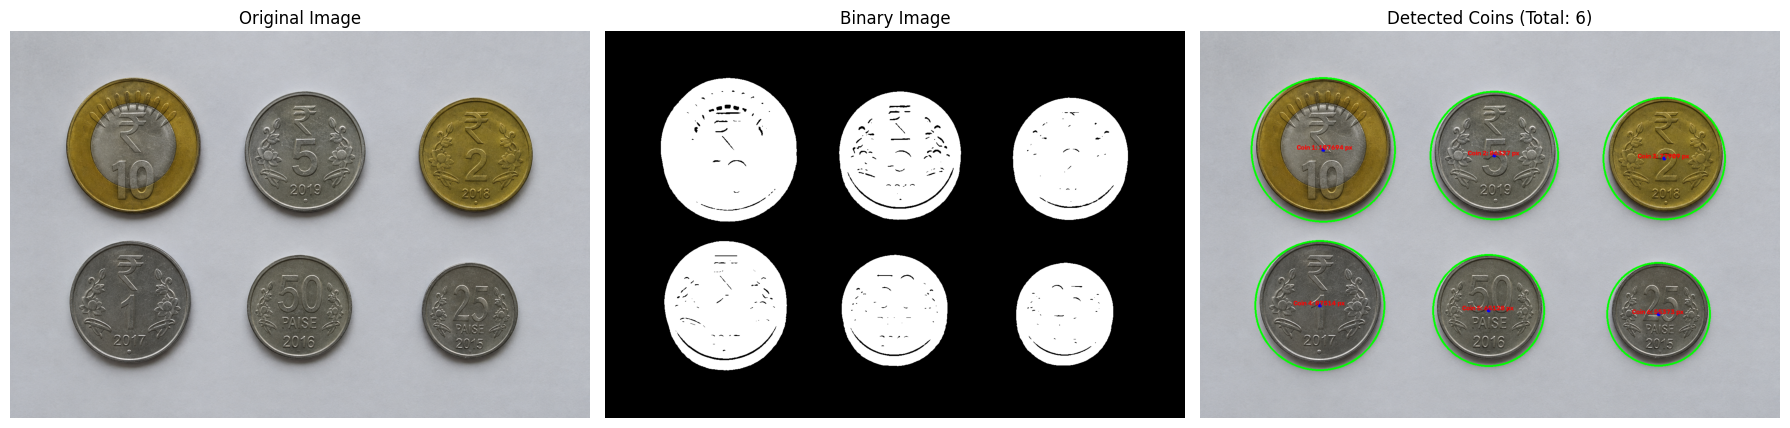

In [7]:
# Write a MATLAB/Python program to read coins.png, leveling all coins and 
# display area of all coins.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("coins.png")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Blur image
gray = cv2.GaussianBlur(gray, (7, 7), 0)

# Convert to binary using Otsu thresholding
_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Find contours
contours, _ = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Copy image
result = img.copy()

coins = []

# Find coin contours
for contour in contours:

    # Calculate actual area of coin
    area = cv2.contourArea(contour)

    # Remove very small objects
    if area > 5000:

        # Find bounding circle
        (x, y), radius = cv2.minEnclosingCircle(contour)

        x = int(x)
        y = int(y)
        radius = int(radius)

        coins.append((x, y, radius, area))

# Sort coins from top to bottom and left to right
coins.sort(key=lambda c: (c[1], c[0]))

print("======================================")
print("          COIN MEASUREMENTS")
print("======================================")

print("Number of coins:", len(coins))
print()

print("Area of each coin:")
print("---------------------------")

# Display each coin
for i, (x, y, radius, area) in enumerate(coins, 1):

    # Draw circle around coin
    cv2.circle(
        result,
        (x, y),
        radius,
        (0, 255, 0),
        3
    )

    # Draw center
    cv2.circle(
        result,
        (x, y),
        5,
        (255, 0, 0),
        -1
    )

    # Display coin number and area
    text = f"Coin {i}: {area:.0f} px"

    cv2.putText(
        result,
        text,
        (x - 70, y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 0, 255),
        2
    )

    print(f"Coin {i}: Area = {area:.2f} pixels")


# Convert BGR to RGB for displaying with Matplotlib
img_rgb = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

result_rgb = cv2.cvtColor(
    result,
    cv2.COLOR_BGR2RGB
)

# Display results
plt.figure(figsize=(18, 6))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

# Binary image
plt.subplot(1, 3, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

# Detected coins with area
plt.subplot(1, 3, 3)
plt.imshow(result_rgb)
plt.title(f"Detected Coins (Total: {len(coins)})")
plt.axis("off")

plt.tight_layout()
plt.show()

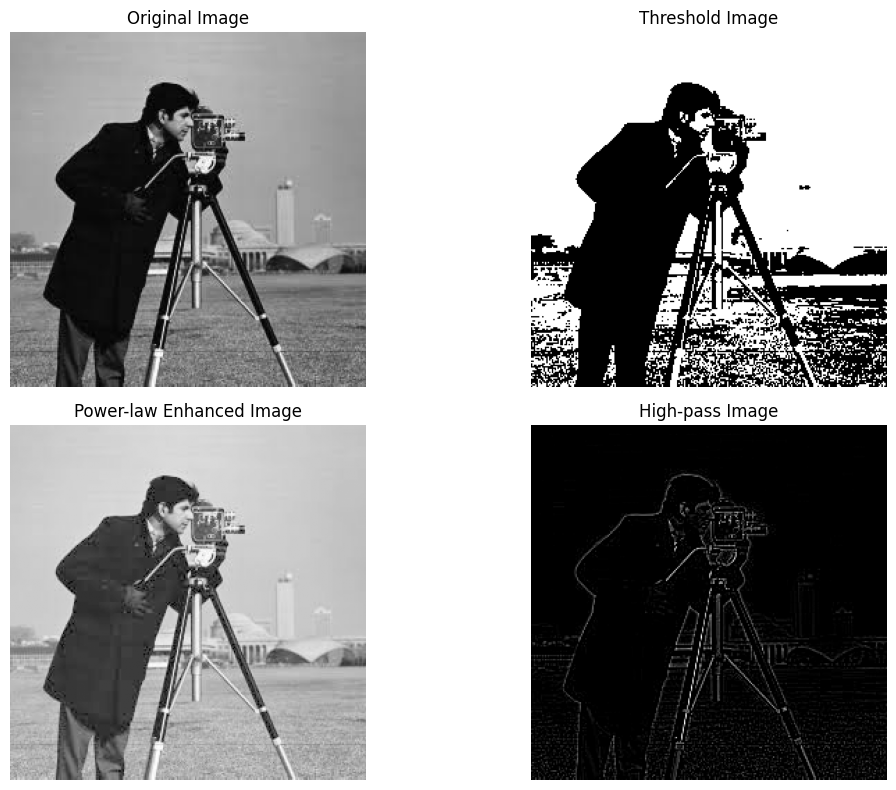

In [8]:
# Display following image operation in MATLAB/Python - i) Threshold 
# image ii) Power enhance contract image iii) High pass image. 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read original image
img_color = cv2.imread("cameraman.jpg")

# Convert to grayscale
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# i) Threshold Image
_, threshold = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

# ii) Power-law Enhancement
gamma = 0.5

normalized = img_gray / 255.0
power_img = np.power(normalized, gamma)
power_img = np.uint8(power_img * 255)

# iii) High-pass Image
blur = cv2.GaussianBlur(img_gray, (5, 5), 0)
high_pass = cv2.subtract(img_gray, blur)

# Display
plt.figure(figsize=(12, 8))

# Original
plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Threshold
plt.subplot(2, 2, 2)
plt.imshow(threshold, cmap="gray")
plt.title("Threshold Image")
plt.axis("off")

# Power-law
plt.subplot(2, 2, 3)
plt.imshow(power_img, cmap="gray")
plt.title("Power-law Enhanced Image")
plt.axis("off")

# High-pass
plt.subplot(2, 2, 4)
plt.imshow(high_pass, cmap="gray")
plt.title("High-pass Image")
plt.axis("off")

plt.tight_layout()
plt.show()

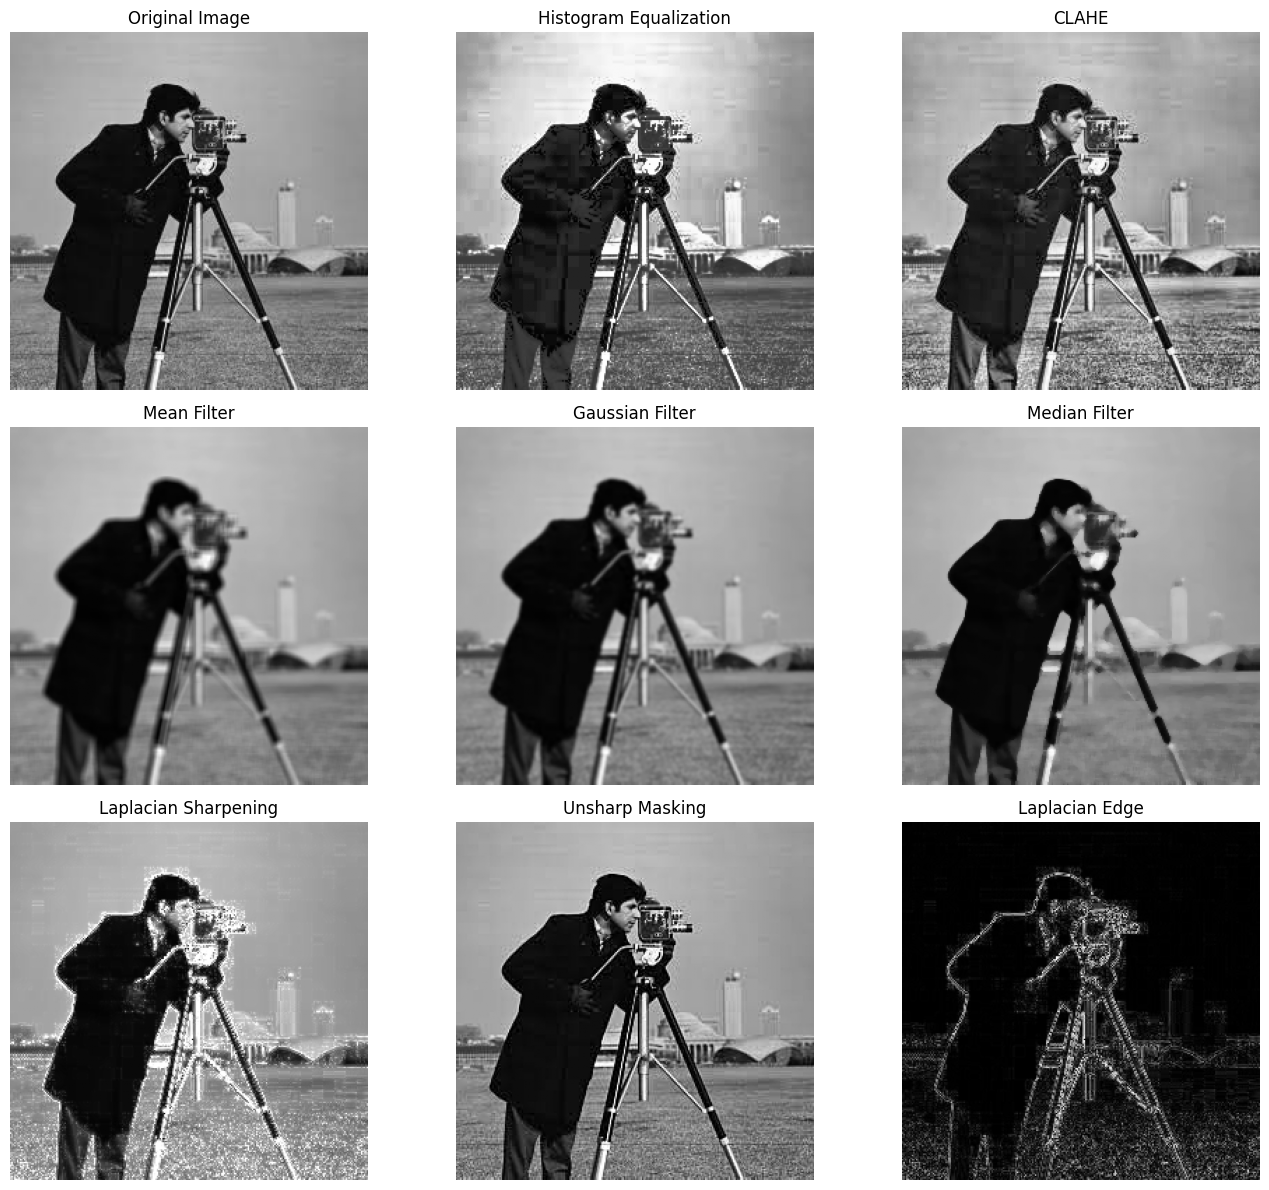

In [9]:
# Perform image enhancement, smoothing and sharpening, in spatial domain 
# using different spatial filters and compare the performances  

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read Image

img = cv2.imread("cameraman.jpg")

if img is None:
    print("Error: Image not found. Check the file path.")
    exit()

# Convert BGR to RGB for display
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 1. IMAGE ENHANCEMENT

# Histogram Equalization
hist_eq = cv2.equalizeHist(gray)

# CLAHE (Contrast Limited Adaptive Histogram Equalization)
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_img = clahe.apply(gray)

# 2. IMAGE SMOOTHING

# Mean / Average Filter
mean_filter = cv2.blur(gray, (5, 5))

# Gaussian Filter
gaussian_filter = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

# Median Filter
median_filter = cv2.medianBlur(
    gray,
    5
)

# 3. IMAGE SHARPENING

# ---------- Laplacian Sharpening ----------

laplacian = cv2.Laplacian(
    gray,
    cv2.CV_64F
)

laplacian = np.uint8(
    np.absolute(laplacian)
)

laplacian_sharp = cv2.add(
    gray,
    laplacian
)

# ---------- Unsharp Masking ----------

blurred = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

# Unsharp masking
unsharp = cv2.addWeighted(
    gray,
    1.5,
    blurred,
    -0.5,
    0
)

# DISPLAY RESULTS

plt.figure(figsize=(14, 12))

# Original
plt.subplot(3, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

# Histogram Equalization
plt.subplot(3, 3, 2)
plt.imshow(hist_eq, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

# CLAHE
plt.subplot(3, 3, 3)
plt.imshow(clahe_img, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

# Mean Filter
plt.subplot(3, 3, 4)
plt.imshow(mean_filter, cmap="gray")
plt.title("Mean Filter")
plt.axis("off")

# Gaussian Filter
plt.subplot(3, 3, 5)
plt.imshow(gaussian_filter, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")

# Median Filter
plt.subplot(3, 3, 6)
plt.imshow(median_filter, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

# Laplacian Sharpening
plt.subplot(3, 3, 7)
plt.imshow(laplacian_sharp, cmap="gray")
plt.title("Laplacian Sharpening")
plt.axis("off")

# Unsharp Masking
plt.subplot(3, 3, 8)
plt.imshow(unsharp, cmap="gray")
plt.title("Unsharp Masking")
plt.axis("off")

# Edge Image
plt.subplot(3, 3, 9)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian Edge")
plt.axis("off")

plt.tight_layout()
plt.show()


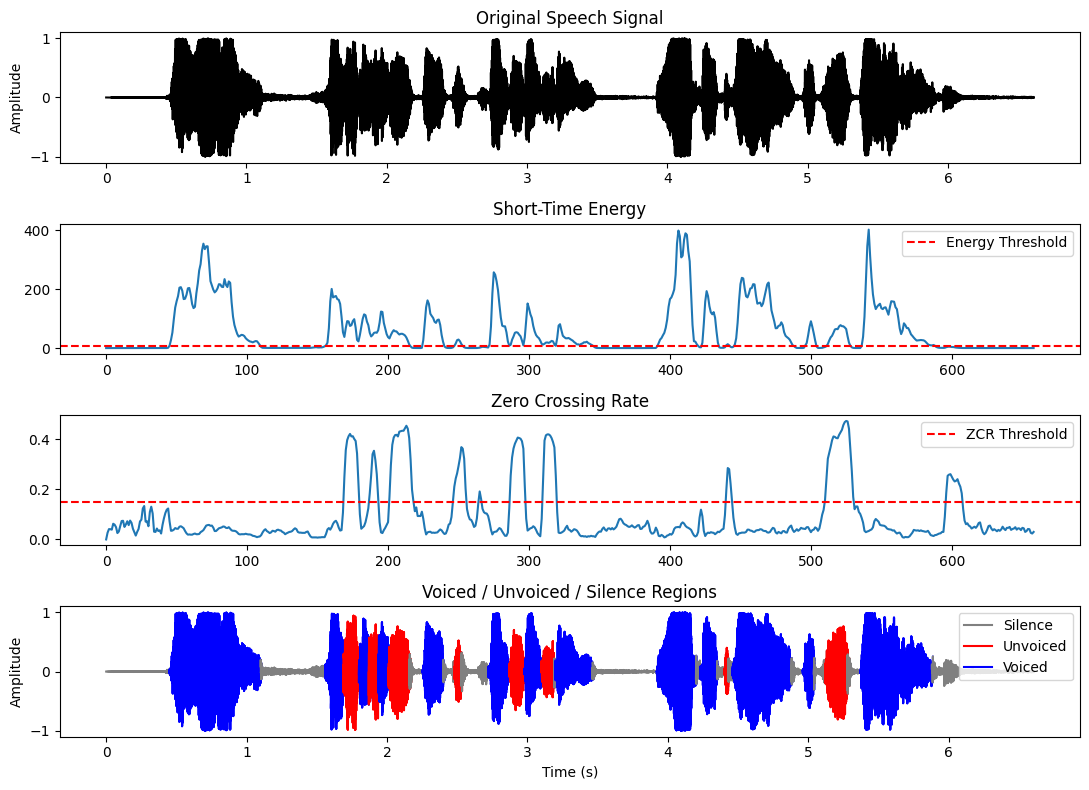

In [10]:

"""
Q12: Separation of Voiced, Unvoiced and Silence Regions
Method: Short-Time Energy (STE) + Zero Crossing Rate (ZCR)

Install:
pip install numpy scipy matplotlib
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

# 1. Read audio
fs, x = wavfile.read('audio.wav')

if x.ndim > 1:
    x = x.mean(axis=1)

x = x.astype(float)
x = x / np.max(np.abs(x))
t = np.arange(len(x)) / fs

# 2. Framing
frame_len = int(0.025 * fs)
hop = int(0.010 * fs)

energy = []
zcr = []

for i in range(0, len(x) - frame_len + 1, hop):
    frame = x[i:i + frame_len]

    energy.append(np.sum(frame ** 2))
    zcr.append(0.5 * np.mean(np.abs(np.diff(np.sign(frame)))))

energy = np.array(energy)
zcr = np.array(zcr)

# 3. Threshold
E_thr = 0.02 * np.max(energy)
Z_thr = 0.15

# 4. Classification
label = []

for i in range(len(energy)):
    if energy[i] < E_thr:
        label.append(0)       # Silence
    elif zcr[i] > Z_thr:
        label.append(1)       # Unvoiced
    else:
        label.append(2)       # Voiced

# 5. Plot
plt.figure(figsize=(11, 8))

# Original signal
plt.subplot(4, 1, 1)
plt.plot(t, x, 'k')
plt.title('Original Speech Signal')
plt.ylabel('Amplitude')

# Short-time energy
plt.subplot(4, 1, 2)
plt.plot(energy)
plt.axhline(E_thr, color='r', linestyle='--',
            label='Energy Threshold')
plt.title('Short-Time Energy')
plt.legend()

# Zero crossing rate
plt.subplot(4, 1, 3)
plt.plot(zcr)
plt.axhline(Z_thr, color='r', linestyle='--',
            label='ZCR Threshold')
plt.title('Zero Crossing Rate')
plt.legend()

# Voiced, Unvoiced and Silence
plt.subplot(4, 1, 4)

# Legend: show all three labels
plt.plot([], [], color='gray', label='Silence')
plt.plot([], [], color='red', label='Unvoiced')
plt.plot([], [], color='blue', label='Voiced')

for i in range(len(label)):
    start = i * hop
    end = min(start + frame_len, len(x))

    if label[i] == 0:
        plt.plot(t[start:end], x[start:end], color='gray')

    elif label[i] == 1:
        plt.plot(t[start:end], x[start:end], color='red')

    else:
        plt.plot(t[start:end], x[start:end], color='blue')

plt.title('Voiced / Unvoiced / Silence Regions')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


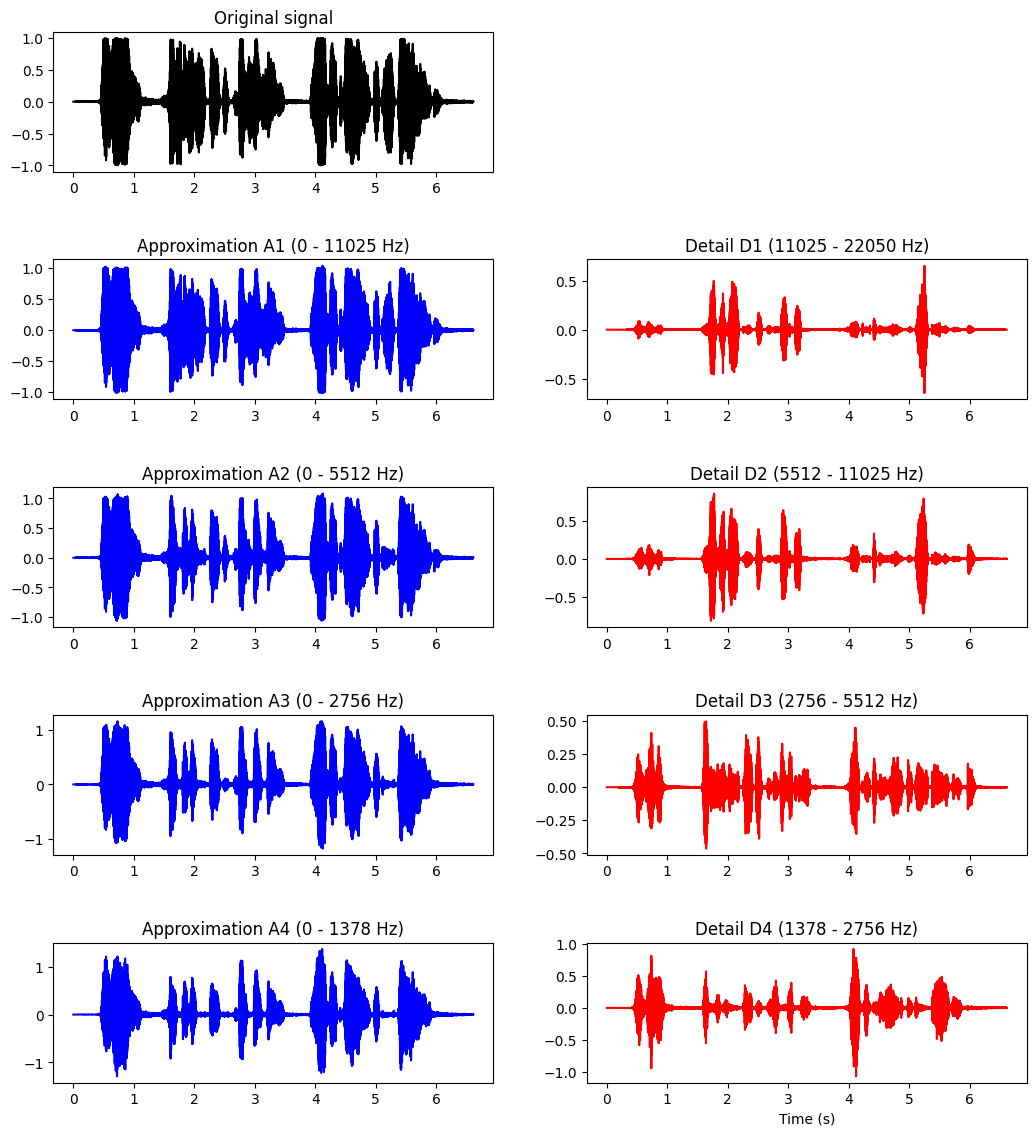

Max reconstruction error: 9.992007221626409e-16


In [11]:
"""
    pip install numpy scipy matplotlib PyWavelets
    py -m pip install numpy matplotlib scipy PyWavelets
    
"""
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy.io import wavfile

# 1. Read audio
fs, x = wavfile.read('audio.wav')

if x.ndim > 1:
    x = x.mean(axis=1)

x = x.astype(float)
x = x / np.max(np.abs(x))
t = np.arange(len(x)) / fs

# 2. DWT Decomposition
wavelet = 'db4'
levels = 4

coeffs = pywt.wavedec(x, wavelet, level=levels)

# 3. Reconstruct A4, D4, D3, D2, D1
signals = []

for i in range(len(coeffs)):
    c = [np.zeros_like(a) for a in coeffs]
    c[i] = coeffs[i]
    signals.append(pywt.waverec(c, wavelet)[:len(x)])

A4 = signals[0]
D4, D3, D2, D1 = signals[1:]

# 4. Find intermediate approximations
A1 = A4 + D4 + D3 + D2
A2 = A4 + D4 + D3
A3 = A4 + D4

approximations = [A1, A2, A3, A4]
details = [D1, D2, D3, D4]

# 5. Plot results
plt.figure(figsize=(11, 12))

plt.subplot(5, 2, 1)
plt.plot(t, x, 'k')
plt.title('Original signal')

for k in range(1, 5):

    plt.subplot(5, 2, 2*k + 1)
    plt.plot(t, approximations[k-1], 'b')
    plt.title(f'Approximation A{k} (0 - {fs/2**(k+1):.0f} Hz)')

    plt.subplot(5, 2, 2*k + 2)
    plt.plot(t, details[k-1], 'r')
    plt.title(f'Detail D{k} ({fs/2**(k+1):.0f} - {fs/2**k:.0f} Hz)')

plt.xlabel('Time (s)')
plt.tight_layout(pad=3)
plt.show()

# 6. Check reconstruction
recon = A4 + D4 + D3 + D2 + D1
print('Max reconstruction error:', np.max(np.abs(x - recon)))

In [14]:
# Write a MATLAB/Python program to recognize speech signal

# Install required packages:
# pip install SpeechRecognition
# pip install pydub  # Optional, for some audio formats

# python -m pip install SpeechRecognition


import speech_recognition as sr

# Create recognizer object
recognizer = sr.Recognizer()

# Load speech file
with sr.AudioFile("voice.wav") as source:
    audio = recognizer.record(source)

# Recognize speech
try:
    result = recognizer.recognize_google(audio)

    print("Recognized Speech:")
    print(result)

except sr.UnknownValueError:
    print("Sorry, speech could not be understood.")

except sr.RequestError:
    print("Could not connect to the recognition service.")

Could not connect to the recognition service.


In [15]:
"""
    pip install SpeechRecognition
    python -m pip install --only-binary=:all: pocketsphinx
"""
import speech_recognition as sr

recognizer = sr.Recognizer()

# 1. Load the audio file
with sr.AudioFile('audio.wav') as source:
    recognizer.adjust_for_ambient_noise(source, duration=0.2)  # estimate noise
    audio = recognizer.record(source)                          # read whole file

# 2. Recognize offline with PocketSphinx
try:
    text = recognizer.recognize_sphinx(audio)
    print('Recognized text:')
    print(text)
except sr.UnknownValueError:
    print('Speech was not understood (try a clearer recording).')
except sr.RequestError as e:
    print('PocketSphinx error (is pocketsphinx installed?):', e)

Recognized text:
hello this is a speech processing laboratory experiments



Recording will start now...
Speak clearly for 5 seconds.
Recording finished.
Speech saved as: recorded_speech.wav
Playing recorded speech...


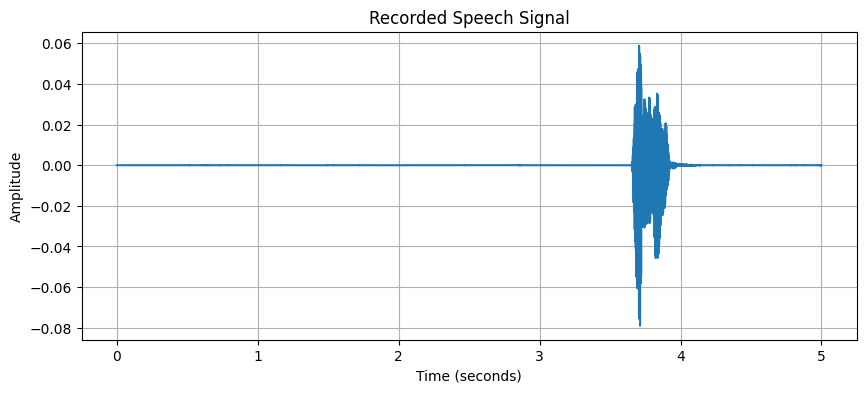

In [16]:
# Write a MATLAB/Python program for text-to-speech conversion and record 
# speech signal.

# """
# Required packages, command: pip install pyttsx3 sounddevice soundfile numpy matplotlib
# """

import pyttsx3
import sounddevice as sd
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

# ---------------- TEXT TO SPEECH ----------------
text = "Welcome to Speech Processing Lab."

engine = pyttsx3.init()
engine.say(text)
engine.runAndWait()

# ---------------- SPEECH RECORDING ----------------
fs = 44100          # Sampling frequency
duration = 5        # Recording time in seconds

print("\nRecording will start now...")
print("Speak clearly for 5 seconds.")

recording = sd.rec(
    int(duration * fs),
    samplerate=fs,
    channels=1,
    dtype='float32'
)

sd.wait()   # Wait until recording is finished

print("Recording finished.")

# Save the recorded speech
filename = "recorded_speech.wav"
sf.write(filename, recording, fs)

print("Speech saved as:", filename)

# ---------------- PLAY RECORDED SPEECH ----------------
print("Playing recorded speech...")
sd.play(recording, fs)
sd.wait()

# ---------------- PLOT SPEECH SIGNAL ----------------
time = np.arange(len(recording)) / fs

plt.figure(figsize=(10, 4))
plt.plot(time, recording)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Recorded Speech Signal")
plt.grid()
plt.show()